In [1]:
import os
import shutil
import random


original_data_dir = '/kaggle/input/datasets/anthonytherrien/dog-vs-cat/animals' 

# This is where your new train/test folders will be created
base_dir = '/kaggle/working/'
train_dir = os.path.join(base_dir, 'train')
test_dir = os.path.join(base_dir, 'test')

# --- 2. CREATE THE FOLDERS ---
for folder in ['cats', 'dogs']:
    os.makedirs(os.path.join(train_dir, folder), exist_ok=True)
    os.makedirs(os.path.join(test_dir, folder), exist_ok=True)

# --- 3. SPLIT THE DATA (80% train, 20% test) ---
split_ratio = 0.8 

for category in ['cat', 'dog']:
    # Determine the source folder (Kaggle usually has lowercase 'cat'/'dog')
    src_folder = os.path.join(original_data_dir, category)
    
    # Get all image files
    files = [f for f in os.listdir(src_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    random.shuffle(files) # Shuffle so we get a random mix
    
    split_point = int(len(files) * split_ratio)
    train_files = files[:split_point]
    test_files = files[split_point:]
    
    # Map 'cat' -> 'cats' and 'dog' -> 'dogs' to match your desired screenshot
    dest_name = 'cats' if category == 'cat' else 'dogs'
    
    # Copy Train files
    print(f"Copying {len(train_files)} {category} files to train...")
    for f in train_files:
        shutil.copy(os.path.join(src_folder, f), os.path.join(train_dir, dest_name, f))
        
    # Copy Test files
    print(f"Copying {len(test_files)} {category} files to test...")
    for f in test_files:
        shutil.copy(os.path.join(src_folder, f), os.path.join(test_dir, dest_name, f))

print("\n✅ Split complete! Check the /kaggle/working/ folder on the right sidebar.")

Copying 400 cat files to train...
Copying 100 cat files to test...
Copying 400 dog files to train...
Copying 100 dog files to test...

✅ Split complete! Check the /kaggle/working/ folder on the right sidebar.


In [2]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential 
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten

In [3]:
 #generators

train_ds = keras.utils.image_dataset_from_directory(
    directory = '/kaggle/working/train',
    labels = 'inferred',
    label_mode='int',
    batch_size=(32),
    image_size=(256,256)
)

validation_ds = keras.utils.image_dataset_from_directory(
    directory = '/kaggle/working/test',
    labels = 'inferred',
    label_mode='int',
    batch_size=(32),
    image_size=(256,256)
)

Found 800 files belonging to 2 classes.


I0000 00:00:1792582479.994386      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792582479.998827      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 200 files belonging to 2 classes.


In [4]:
#Normalize
def process(image,label):
    image=tf.cast(image/255. ,tf.float32)
    return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [5]:
# create CNN model 

model = Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))
model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))
model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,297 (56.64 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(optimizer='adam', loss='binary_crossentropy',metrics=['accuracy'])

In [8]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10


2026-10-21 11:34:51.603478: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-21 11:34:51.915212: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 3/25 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.4740 - loss: 0.8798

I0000 00:00:1792582495.360884      76 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


25/25 ━━━━━━━━━━━━━━━━━━━━ 16s 181ms/step - accuracy: 0.5537 - loss: 0.7410 - val_accuracy: 0.6400 - val_loss: 0.6118
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.7825 - loss: 0.4781 - val_accuracy: 0.8300 - val_loss: 0.3704
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.9150 - loss: 0.2424 - val_accuracy: 0.8950 - val_loss: 0.3044
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.9538 - loss: 0.1218 - val_accuracy: 0.8950 - val_loss: 0.3273
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.9563 - loss: 0.1085 - val_accuracy: 0.9000 - val_loss: 0.4300
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.9750 - loss: 0.0626 - val_accuracy: 0.9100 - val_loss: 0.3024
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.9975 - loss: 0.0117 - val_accuracy: 0.8950 - val_loss: 0.4736
Epoch 8/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 127ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 0.9000 - val

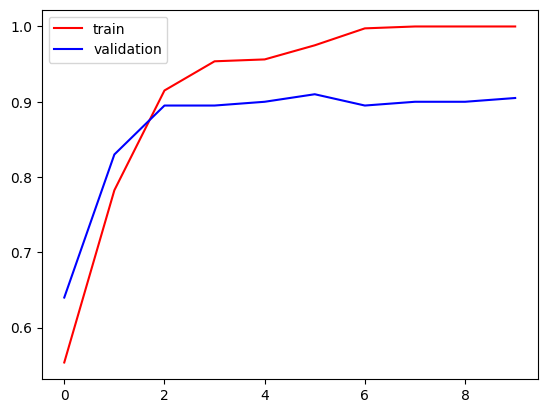

In [9]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'],color='red',label='train')
plt.plot(history.history['val_accuracy'],color='blue', label='validation')
plt.legend()
plt.show()

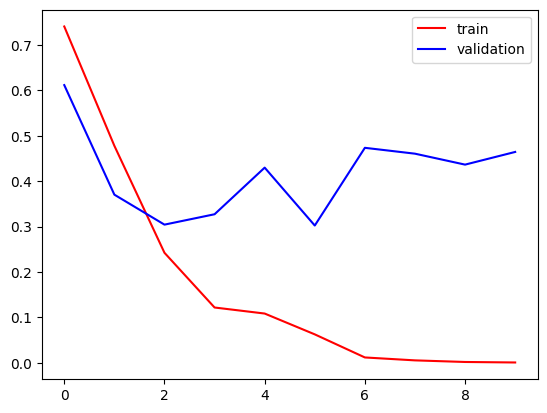

In [10]:
plt.plot(history.history['loss'],color='red',label='train')
plt.plot(history.history['val_loss'],color='blue', label='validation')
plt.legend()
plt.show()